# Task 1 · Notebook 04 — Lounge Eligibility at Heathrow Terminal 3

**Business question.** British Airways needs to plan lounge capacity at Heathrow Terminal 3. For any future flight, how many departing passengers are likely to be eligible for each lounge tier?

**Data.** `data/raw/ba_summer_schedule_2025.xlsx` is the summer schedule provided in the Forage British Airways job simulation. It holds 10,000 departures from Heathrow (April–October 2025) with seats per cabin and the number of passengers eligible for Tier 1, Tier 2 and Tier 3 lounges.

**Deliverable.** A reusable lookup table that BA can apply to future schedules, with a written justification for how flights are grouped.

**Note.** This replaces an earlier version that estimated lounge demand from review data. Reviewers are not a representative sample of passengers, and that version gave lounge access to every Premium Economy passenger, which BA does not offer.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SCHEDULE_FILE = Path("data/raw/ba_summer_schedule_2025.xlsx")
df = pd.read_excel(SCHEDULE_FILE)

df.columns = df.columns.str.lower()                      # FLIGHT_DATE -> flight_date
df["total_seats"] = df[["first_class_seats", "business_class_seats", "economy_seats"]].sum(axis=1)

print(f"{len(df):,} flights, {df.shape[1]} columns")
print("Missing values:", df.isna().sum().sum(), "  Duplicate rows:", df.duplicated().sum())
df.head()

10,000 flights, 18 columns
Missing values: 0   Duplicate rows: 0


,flight_date,flight_time,time_of_day,airline_cd,flight_no,departure_station_cd,arrival_station_cd,arrival_country,arrival_region,haul,aircraft_type,first_class_seats,business_class_seats,economy_seats,tier1_eligible_pax,tier2_eligible_pax,tier3_eligible_pax,total_seats
0,2025-09-02,14:19:00,Afternoon,BA,BA5211,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,10,38,235
1,2025-06-10,06:42:00,Morning,BA,BA7282,LHR,LAX,USA,North America,LONG,B777,8,49,178,0,7,28,235
2,2025-10-27,15:33:00,Afternoon,BA,BA1896,LHR,FRA,Germany,Europe,SHORT,A320,0,17,163,0,11,40,180
3,2025-06-15,18:29:00,Evening,BA,BA5497,LHR,IST,Turkey,Europe,SHORT,A320,0,8,172,0,16,54,180
4,2025-08-25,20:35:00,Evening,BA,BA1493,LHR,FRA,Germany,Europe,SHORT,A320,0,13,167,0,6,27,180


## 1. The standard approach: eligibility as a share of seats

For each group of flights, divide the total number of eligible passengers by the total number of seats. This gives a percentage that can be applied to any future flight in that group.

In [2]:
TIERS = ["tier1_eligible_pax", "tier2_eligible_pax", "tier3_eligible_pax"]

def eligibility_rates(group_cols):
    """% of seats taken by eligible passengers, per tier, for each group."""
    totals = df.groupby(group_cols)[TIERS + ["total_seats"]].sum()
    rates = totals[TIERS].div(totals["total_seats"], axis=0) * 100
    rates.columns = ["Tier 1 %", "Tier 2 %", "Tier 3 %"]
    rates["flights"] = df.groupby(group_cols).size()
    return rates.round(2)

print("By destination region:")
display(eligibility_rates("arrival_region"))

print("By time of day:")
display(eligibility_rates("time_of_day"))

By destination region:


,Tier 1 %,Tier 2 %,Tier 3 %,flights
arrival_region,,,,
Asia,0.19,2.70,10.35,679
Europe,0.34,4.40,16.85,5975
Middle East,0.21,2.69,10.29,688
North America,0.20,2.76,10.55,2658


By time of day:


,Tier 1 %,Tier 2 %,Tier 3 %,flights
time_of_day,,,,
Afternoon,0.27,3.50,13.39,2305
Evening,0.27,3.53,13.50,2973
Lunchtime,0.29,3.67,13.96,1192
Morning,0.27,3.52,13.48,3530


**Observations.** Destination region matters (Europe ≈4.4% Tier 2 and 16.9% Tier 3 of seats, the long-haul regions ≈2.7% and 10.4%), while time of day barely changes anything.

But why would short-haul Europe have a *higher* share of lounge-eligible passengers than long-haul flights? Every European flight in this data uses the smallest aircraft (A320, 180 seats), and a percentage depends on both the eligible passengers *and* the seats. The next section separates the two.

## 2. Does aircraft size matter?

Average seats and average **number** of eligible passengers per flight, by aircraft (smallest to largest), then the correlation between seat counts and eligible passengers.

In [3]:
by_aircraft = df.groupby("aircraft_type").agg(
    flights=("flight_no", "size"),
    avg_seats=("total_seats", "mean"),
    avg_tier1_pax=("tier1_eligible_pax", "mean"),
    avg_tier2_pax=("tier2_eligible_pax", "mean"),
    avg_tier3_pax=("tier3_eligible_pax", "mean"),
).sort_values("avg_seats")

by_aircraft["tier3_%_of_seats"] = by_aircraft["avg_tier3_pax"] / by_aircraft["avg_seats"] * 100
by_aircraft.round(1)

,flights,avg_seats,avg_tier1_pax,avg_tier2_pax,avg_tier3_pax,tier3_%_of_seats
aircraft_type,,,,,,
A320,5975,180.0,0.6,7.9,30.3,16.9
B787,1236,223.5,0.6,8.1,30.9,13.8
B777,1878,290.1,0.6,8.0,30.5,10.5
A350,535,331.0,0.6,7.9,30.4,9.2
A380,376,469.0,0.5,7.8,30.2,6.4


In [4]:
check = df[TIERS + ["first_class_seats", "business_class_seats", "total_seats"]].corr().loc[
    ["first_class_seats", "business_class_seats", "total_seats"], TIERS
]
check.round(2)

,tier1_eligible_pax,tier2_eligible_pax,tier3_eligible_pax
first_class_seats,-0.01,-0.0,0.0
business_class_seats,-0.02,0.0,0.0
total_seats,-0.02,-0.0,-0.0


**Finding.** Eligible passengers per flight are ≈0.6 / 8 / 30 (Tiers 1 / 2 / 3) on **every** aircraft type, and their correlation with seat counts is ≈0. So a share-of-seats rate falls as aircraft get bigger purely through arithmetic: Tier 3 is 16.9% of seats on an A320 but only 6.4% on an A380. Europe looked "more lounge-heavy" only because it is flown entirely by small aircraft.

**Implication.** A lookup of percentages would overestimate demand for large aircraft and underestimate it for small long-haul aircraft. A lookup of **expected eligible passengers per departure** fits this data better. Section 3 tests both.

**Caveat.** The schedule is a dataset provided for a training exercise, and this constant headcount is likely a feature of how it was generated. In real BA data, larger aircraft with more premium seats would almost certainly carry more eligible passengers.

## 3. Testing both methods on future flights

To mimic real use, both lookup tables are built from **April–August** flights and then used to predict eligible passengers on **September–October** flights, which the tables have not seen.

- **Method A (percentage).** Region-level share of seats × the flight's seat count.
- **Method B (headcount).** Region-level average eligible passengers per departure.

Two measures are compared. **Mean absolute error** is how far off each flight's prediction is on average. **Bias by aircraft** shows whether a method is consistently too high or too low for a particular plane, which matters most for capacity planning because consistent errors add up across many flights.

In [5]:
past   = df[df["flight_date"] <  "2025-09-01"]
future = df[df["flight_date"] >= "2025-09-01"]
print(f"Built on {len(past):,} flights (Apr–Aug), tested on {len(future):,} flights (Sep–Oct)\n")

# Method A, share of seats by region
sums = past.groupby("arrival_region")[TIERS + ["total_seats"]].sum()
share = sums[TIERS].div(sums["total_seats"], axis=0)
pred_a = future[["arrival_region"]].join(share, on="arrival_region")[TIERS].mul(future["total_seats"], axis=0)

# Method B, average headcount per departure by region
headcount = past.groupby("arrival_region")[TIERS].mean()
pred_b = future[["arrival_region"]].join(headcount, on="arrival_region")[TIERS]

actual = future[TIERS]
print("Mean absolute error per flight (Tier 1, Tier 2, Tier 3)")
print("  A, percentage :", (pred_a - actual).abs().mean().round(2).tolist())
print("  B, headcount  :", (pred_b - actual).abs().mean().round(2).tolist())

bias = pd.DataFrame({
    "A, percentage": (pred_a["tier3_eligible_pax"] - actual["tier3_eligible_pax"]).groupby(future["aircraft_type"]).mean(),
    "B, headcount":  (pred_b["tier3_eligible_pax"] - actual["tier3_eligible_pax"]).groupby(future["aircraft_type"]).mean(),
}).round(1)
print("\nAverage Tier 3 error per flight, by aircraft (positive = overestimate)")
bias

Built on 7,225 flights (Apr–Aug), tested on 2,775 flights (Sep–Oct)

Mean absolute error per flight (Tier 1, Tier 2, Tier 3)
  A, percentage : [0.75, 4.37, 13.1]
  B, headcount  : [0.75, 4.2, 12.37]

Average Tier 3 error per flight, by aircraft (positive = overestimate)


,"A, percentage","B, headcount"
aircraft_type,,
A320,-0.5,-0.5
A350,4.4,0.3
A380,21.9,3.3
B777,-0.3,0.1
B787,-6.8,0.3


**Result.** On September–October flights, the headcount method (B) was slightly more accurate per flight (Tier 3 error 12.4 vs 13.1 passengers) and, more importantly, **unbiased across aircraft**. The percentage method (A) overestimated A380 flights by ~22 Tier 3 passengers each and underestimated B787 flights by ~7. Consistent errors like these accumulate when many flights are summed for capacity planning. Method B is used for the final lookup table.

Individual flights still vary considerably (±12 Tier 3 passengers), which neither method can predict from the schedule alone. The lookup table therefore includes a busy-flight figure (90th percentile) alongside the average.

In [6]:
groups = df.groupby(["haul", "arrival_region"])

lookup = pd.DataFrame({
    "flights_in_data": groups.size(),
    "tier1_avg": groups["tier1_eligible_pax"].mean(),
    "tier2_avg": groups["tier2_eligible_pax"].mean(),
    "tier3_avg": groups["tier3_eligible_pax"].mean(),
    "tier1_busy_p90": groups["tier1_eligible_pax"].quantile(0.9),
    "tier2_busy_p90": groups["tier2_eligible_pax"].quantile(0.9),
    "tier3_busy_p90": groups["tier3_eligible_pax"].quantile(0.9),
}).round(1).reset_index()

OUT_FILE = Path("data/processed/lounge_lookup_table.csv")
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
lookup.to_csv(OUT_FILE, index=False)
print("Saved to", OUT_FILE)
lookup

Saved to data\processed\lounge_lookup_table.csv


,haul,arrival_region,flights_in_data,tier1_avg,tier2_avg,tier3_avg,tier1_busy_p90,tier2_busy_p90,tier3_busy_p90
0,LONG,Asia,679,0.6,7.8,30.1,2.0,15.0,51.0
1,LONG,Middle East,688,0.6,7.9,30.0,2.0,15.0,50.0
2,LONG,North America,2658,0.6,8.1,30.8,2.0,15.0,51.0
3,SHORT,Europe,5975,0.6,7.9,30.3,2.0,15.0,50.0


## 4. When is lounge demand highest?

Time of day does not change how many eligible passengers each flight carries, but it does change how many flights depart. Total demand per time slot is therefore driven by the number of departures.

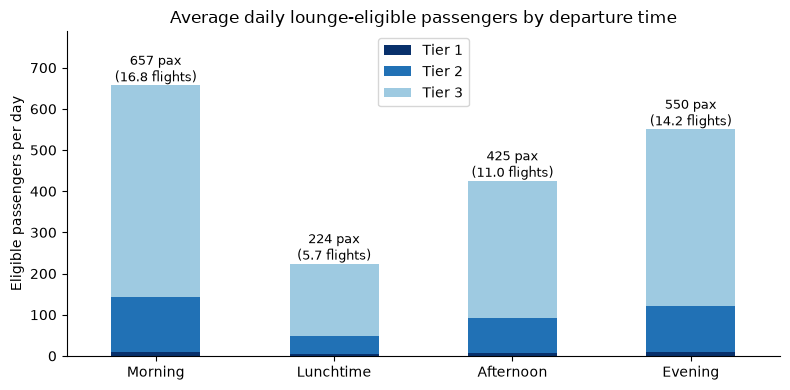

,Tier 1,Tier 2,Tier 3
time_of_day,,,
Morning,10.0,134.0,513.0
Lunchtime,4.0,46.0,174.0
Afternoon,7.0,87.0,332.0
Evening,9.0,112.0,429.0


In [7]:
# Total eligible passengers per day in each time slot, averaged over all days
per_day = (
    df.groupby(["flight_date", "time_of_day"])[TIERS].sum()
      .unstack(fill_value=0).stack()          # days with no flights in a slot count as 0
      .groupby("time_of_day").mean()
      .reindex(["Morning", "Lunchtime", "Afternoon", "Evening"])
)
per_day.columns = ["Tier 1", "Tier 2", "Tier 3"]
departures = (df.groupby("time_of_day").size() / df["flight_date"].nunique()).reindex(per_day.index)

fig, ax = plt.subplots(figsize=(8, 4))
per_day.plot(kind="bar", stacked=True, ax=ax, color=["#08306b", "#2171b5", "#9ecae1"], rot=0)
for i, (total, deps) in enumerate(zip(per_day.sum(axis=1), departures)):
    ax.text(i, total + 10, f"{total:.0f} pax\n({deps:.1f} flights)", ha="center", fontsize=9)
ax.set_ylabel("Eligible passengers per day")
ax.set_xlabel("")
ax.set_title("Average daily lounge-eligible passengers by departure time")
ax.set_ylim(0, per_day.sum(axis=1).max() * 1.2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

per_day.round(0)

## 5. Testing a planning margin on later days

Planners should not staff for the *average* day. The Streamlit app adds a **plan-for** figure: the expected total for a group of flights plus 1.28 standard deviations, a level that total demand should stay below about 90% of the time. Because busy and quiet flights partly cancel out, the margin grows with the square root of the number of flights.

To test it honestly, the averages and spreads are built from **April–August** flights and checked against each of the **60 days in September–October**, which they have not seen.

In [8]:
import numpy as np

Z_90 = 1.2816                                            # 90th percentile of the normal distribution
mean_per_flight = past.groupby("arrival_region")[TIERS].mean()
sd_per_flight = past.groupby("arrival_region")[TIERS].std()

coverage = {}
for tier in TIERS:
    covered = []
    for day, flights in future.groupby("flight_date"):
        n = flights["arrival_region"].value_counts()
        expected = (n * mean_per_flight[tier].reindex(n.index)).sum()
        margin = Z_90 * np.sqrt((n * sd_per_flight[tier].reindex(n.index) ** 2).sum())
        covered.append(flights[tier].sum() <= expected + margin)
    coverage[tier] = np.mean(covered)

print(f"Days tested: {future['flight_date'].nunique()} (September–October)")
pd.Series(coverage, name="share of days at or below plan-for").map("{:.1%}".format)

Days tested: 60 (September–October)


tier1_eligible_pax    93.3%
tier2_eligible_pax    93.3%
tier3_eligible_pax    91.7%
Name: share of days at or below plan-for, dtype: str

**Result.** On the 60 later days, actual whole-day demand stayed at or below the plan-for figure on **92–93%** of days for every tier, close to the 90% the method aims for. The margin is therefore a sound basis for planning, and it is what the Lounge Planner page in the app uses.

## Summary

**Lookup table** (`data/processed/lounge_lookup_table.csv`). Expected lounge-eligible passengers per departure, by haul and region.

| Group | Tier 1 | Tier 2 | Tier 3 | Busy flight (P90) T1 / T2 / T3 |
|---|---|---|---|---|
| Long haul, Asia | 0.6 | 7.8 | 30.1 | 2 / 15 / 51 |
| Long haul, Middle East | 0.6 | 7.9 | 30.0 | 2 / 15 / 50 |
| Long haul, North America | 0.6 | 8.1 | 30.8 | 2 / 15 / 51 |
| Short haul, Europe | 0.6 | 7.9 | 30.3 | 2 / 15 / 50 |

**How BA would use it.** For each flight in a future schedule, look up its group and add up the expected passengers per tier for every flight in a time window. For a safety margin on a group of flights, use the plan-for figure from Section 5. The P90 columns describe a single busy flight, not a group.

**Key findings**
1. In this dataset the number of eligible passengers per flight is nearly constant (≈0.6 / 8 / 30) and unrelated to aircraft size or seat mix.
2. A percentage-of-seats lookup, the obvious approach, would therefore be biased by aircraft. Tested on September–October flights, it overestimated A380 flights by ~22 Tier 3 passengers each and underestimated B787 flights by ~7. The headcount method was unbiased across aircraft, so it is used for the table.
3. Individual flights vary by about ±12 Tier 3 passengers, which the schedule alone cannot predict.
4. Time of day does not change demand per flight, but the **morning peak** (≈657 eligible passengers a day from ≈17 departures) is nearly three times lunchtime, driven by the number of departures.
5. A plan-for margin built from April–August data covered actual demand on 92–93% of the 60 later days.

**Limitations**
- This is a dataset provided for a training exercise, and the constant headcount is likely a feature of how it was generated. The table should be rebuilt from real data before use.
- Eligible is not the same as attending. Actual occupancy needs visit and dwell-time data.
- The table covers four destination regions only. Other routes would need a new group.